# NUTDTS 816 Time Series Analysis
## L01 Introduction to time series data

Lab notebook for Chapter 1 of the lecture notes. Run the setup cell first. Every code cell reproduces an example from the notes; the exercises at the end are from the chapter's self-check list.

**Instructor:** Dr Tolulope Adesina · NUTM MSc Data Science · 2026

In [1]:
# ---- Setup: run once per Colab session ----
# 1. Install the course libraries (about two minutes the first time)
!pip install -q statsmodels pmdarima statsforecast neuralforecast lightgbm arch plotly

# 2. Fetch the course data module and data snapshots from the course repository.
#    Replace REPO with your fork or the official course repository URL.
REPO = "https://raw.githubusercontent.com/Favour-Fregene/NUTDTS816_Course_Repository/main"
import urllib.request, os
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
DATA_FILES = ["nigeria_cpi", "nigeria_fx", "nigeria_grid", "nigeria_malaria", "nigeria_rainfall", "bonny_light", "daily_demand",
              "airpassengers", "a10", "h02", "ausbeer", "elecequip", "usmelec", "goog", "nile", "austourists", "oil", "dax", "uschange", "elecdemand"]
for f in DATA_FILES:
    urllib.request.urlretrieve(f"{REPO}/data/{f}.csv", f"data/{f}.csv")

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
import tsdata
print("Setup complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.3/331.3 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

### 1.6 Working with time series in pandas

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import tsdata   # course data module (real fpp2/R datasets; simulated Nigerian-shaped series)

ap = tsdata.airpassengers()      # monthly international airline passengers, 1949-1960 (thousands)
print(type(ap), ap.index.freq)
print(ap.head(6))
print(ap.index[:3])

<class 'pandas.core.series.Series'> <MonthBegin>
date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
1949-06-01    135
Freq: MS, Name: passengers, dtype: int64
DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01'], dtype='datetime64[ns]', name='date', freq='MS')


In [3]:
# A messy extract, as you might receive it from a portal
raw = pd.DataFrame({
    'period': ['2024-01', '2024-02', '2024-03', '2024-05', '2024-05', '2024-06', '2024-08'],
    'cpi':    [  743.1,    752.6,    766.0,     787.9,     787.9,    803.4,     828.7]})
raw['date'] = pd.to_datetime(raw['period'], format='%Y-%m')
s = raw.drop_duplicates('date').set_index('date')['cpi']
s = s.asfreq('MS')                       # impose a regular monthly grid; gaps become NaN
print(s)
print('missing:', s.isna().sum())

date
2024-01-01    743.1
2024-02-01    752.6
2024-03-01    766.0
2024-04-01      NaN
2024-05-01    787.9
2024-06-01    803.4
2024-07-01      NaN
2024-08-01    828.7
Freq: MS, Name: cpi, dtype: float64
missing: 2


In [4]:
s_filled = s.interpolate(method='linear')   # simple, defensible for a smooth monthly index
print(s_filled.round(1))

date
2024-01-01    743.1
2024-02-01    752.6
2024-03-01    766.0
2024-04-01    777.0
2024-05-01    787.9
2024-06-01    803.4
2024-07-01    816.0
2024-08-01    828.7
Freq: MS, Name: cpi, dtype: float64


In [5]:
dem = tsdata.elecdemand()    # half-hourly electricity demand, Victoria (Australia), 2014
print(dem.head(3))
daily = dem['Demand'].resample('D').sum()          # daily total demand (GW-halfhours)
monthly_mean = dem['Demand'].resample('MS').mean() # monthly mean half-hourly demand
print(daily.head(3).round(1)); print(monthly_mean.round(2).head(3))

                       Demand  WorkDay  Temperature
date                                               
2014-01-01 00:00:00  3.914647        0         18.2
2014-01-01 00:30:00  3.672550        0         17.9
2014-01-01 01:00:00  3.497539        0         17.6
date
2014-01-01    174.9
2014-01-02    188.6
2014-01-03    188.9
Freq: D, Name: Demand, dtype: float64
date
2014-01-01    4.83
2014-02-01    4.82
2014-03-01    4.40
Freq: MS, Name: Demand, dtype: float64


In [6]:
cpi  = tsdata.nigeria_cpi()     # monthly CPI, Jan 2015 - Jun 2026 (simulated)
fx   = tsdata.nigeria_fx()      # monthly NGN/USD, Jan 2015 - Jun 2026 (simulated)
grid = tsdata.nigeria_grid()    # monthly average grid generation, MW (simulated)
print(pd.concat([cpi, fx, grid], axis=1).tail(4))

            cpi    ngn_usd  generation_mw
date                                     
2026-04-01  NaN  1360.7185         3500.0
2026-05-01  NaN  1369.4947            NaN
2026-06-01  NaN  1366.4902            NaN
2026-07-01  NaN  1372.7523            NaN


## Exercises

1. For each of the following, state the natural frequency, the seasonal period(s) $m$, and whether you expect the series to be additive or multiplicative: hourly grid frequency; monthly rice prices in Lagos; quarterly Nigerian GDP; daily visits to a hospital emergency department; weekly cholera cases.
2. The `a10` series in the course data module is monthly antidiabetic drug sales in Australia. Produce the time plot, the log time plot, a seasonal plot and the ACF of the first difference of the log. Describe the trend, the seasonality and its type. What happens every January, and why might that be?
3. Simulate a random walk $x_t = x_{t-1} + \varepsilon_t$ with $\varepsilon_t \sim N(0,1)$ for $T = 200$ and plot its ACF. Explain why the ACF looks like that of a trending series even though the process has no deterministic trend.

In [12]:
# Your work here
# ["nigeria_cpi", "nigeria_fx", "nigeria_grid", "nigeria_malaria", "nigeria_rainfall", "bonny_light", "daily_demand",
       #       "airpassengers", "a10", "h02", "ausbeer", "elecequip", "usmelec", "goog", "nile", "austourists", "oil", "dax", "uschange", "elecdemand"]


ap = tsdata.airpassengers()      # monthly international airline passengers, 1949-1960 (thousands)
print(type(ap), ap.index.freq)
cpi = tsdata.nigeria_cpi()     # monthly CPI, Jan 2015 - Jun 2026 (simulated)
print(type(cpi), cpi.index.freq)
fx = tsdata.nigeria_fx()      # monthly NGN/USD, Jan 2015 - Jun 2026 (simulated)
print(type(fx), fx.index.freq)
grid = tsdata.nigeria_grid()    # monthly average grid generation, MW (simulated)
print(type(grid), grid.index.freq)
a10 = tsdata.a10()
print(type(a10), a10.index.freq)
malaria = tsdata.nigeria_malaria()
print(type(malaria), malaria.index.freq)
rainfall = tsdata.nigeria_rainfall()
print(type(rainfall), rainfall.index.freq)
bonny = tsdata.bonny_light()
print(type(bonny), bonny.index.freq)
demand = tsdata.daily_demand()
print(type(demand), demand.index.freq)
h02 = tsdata.h02()
print(type(h02), h02.index.freq)
ausbeer = tsdata.ausbeer()
print(type(ausbeer), ausbeer.index.freq)
elecequip = tsdata.elecequip()
print(type(elecequip), elecequip.index.freq)
usmelec = tsdata.uschange()
print(type(usmelec), usmelec.index.freq)

nile = tsdata.nile()
print(type(nile), nile.index.freq)
austourists = tsdata.austourists()
print(type(austourists), austourists.index.freq)
oil = tsdata.oil()
print(type(oil), oil.index.freq)

uschange = tsdata.uschange()
print(type(uschange), uschange.index.freq)
elecdemand = tsdata.elecdemand()
print(type(elecdemand), elecdemand.index.freq)

print()
print()
print()
print()

import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose

def check_series(s, name='series'):
    freq = s.index.freq or pd.infer_freq(s.index)
    period_map = {'H': 24, 'D': 7, 'W': 52, 'MS': 12, 'M': 12,
                  'QS-JAN': 4, 'Q': 4, 'QS': 4, 'A': 1, 'AS': 1}
    period = period_map.get(str(freq), None)

    result = {'series': name, 'frequency': freq, 'period': period, 'n_obs': len(s)}

    if period is None or period < 2 or len(s) < 2 * period:
        result['verdict'] = 'not enough data to test seasonality'
        return result

    add = seasonal_decompose(s, model='additive', period=period)
    resid = add.resid.dropna()
    half = len(resid) // 2
    early_std = resid.iloc[:half].std()
    late_std = resid.iloc[half:].std()

    result['early_half_std'] = round(early_std, 4)
    result['late_half_std'] = round(late_std, 4)
    result['verdict'] = 'multiplicative' if late_std > 1.3 * early_std else 'additive'
    return result

# Load whichever of these actually exist in your tsdata module
at = tsdata.austourists()
cpi = tsdata.nigeria_cpi()
fx = tsdata.nigeria_fx()
demand = tsdata.daily_demand()


rows = [
    check_series(at, 'austourists'),
    check_series(cpi, 'Nigeria CPI'),
    check_series(fx, 'Nigeria FX'),
    check_series(demand, 'Daily electricity demand'),
]

pd.DataFrame(rows)

<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <Week: weekday=6>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <Day>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.series.Series'> <QuarterBegin: startingMonth=1>
<class 'pandas.core.series.Series'> <MonthBegin>
<class 'pandas.core.frame.DataFrame'> <QuarterBegin: startingMonth=1>
<class 'pandas.core.series.Series'> <YearBegin: month=1>
<class 'pandas.core.series.Series'> <QuarterBegin: startingMonth=1>
<class 'pandas.core.series.Series'> <YearBegin: month=1>
<class 'pandas.core.frame.DataFrame'> <QuarterBegin: startingMonth=1>
<class 'pandas.core.frame.DataFrame'> <30 * Minutes>






,series,frequency,period,n_obs,verdict
0,austourists,<QuarterBegin: startingMonth=1>,None,68,not enough data to test seasonality
1,Nigeria CPI,<MonthBegin>,None,144,not enough data to test seasonality
2,Nigeria FX,<MonthBegin>,None,139,not enough data to test seasonality
3,Daily electricity demand,<Day>,None,1695,not enough data to test seasonality


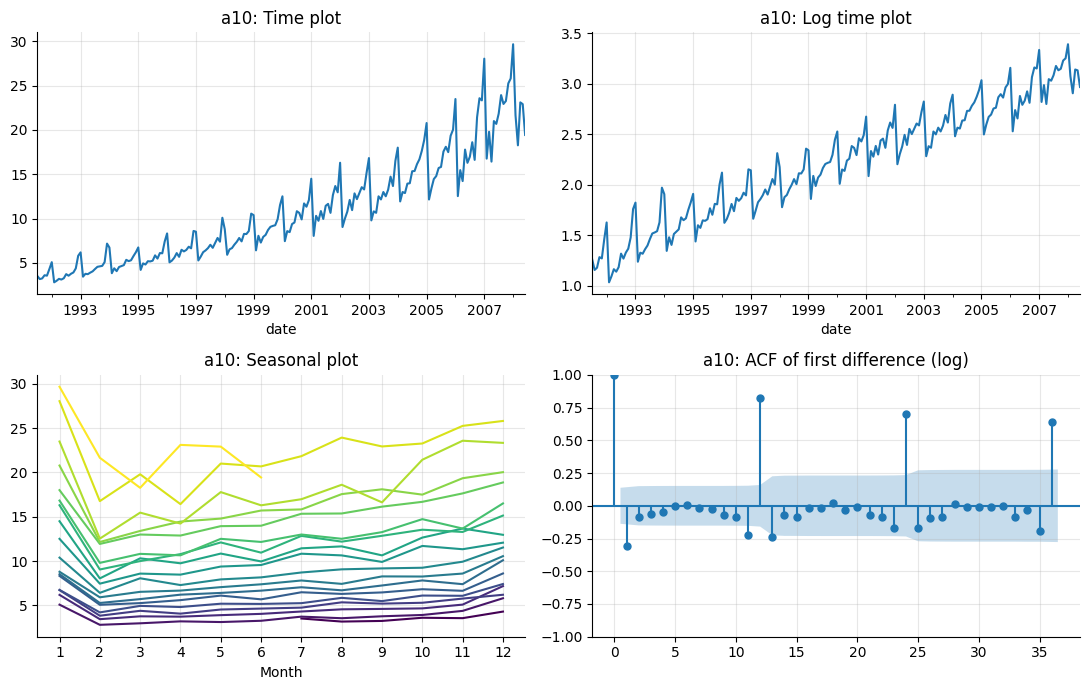

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

a10 = tsdata.a10()   # adjust to however your course module loads it

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

a10.plot(ax=axes[0, 0], title='a10: Time plot')
np.log(a10).plot(ax=axes[0, 1], title='a10: Log time plot')

# Seasonal plot
df = pd.DataFrame({'v': a10.values, 'year': a10.index.year, 'month': a10.index.month})
piv = df.pivot(index='month', columns='year', values='v')
piv.plot(ax=axes[1, 0], legend=False, colormap='viridis', title='a10: Seasonal plot')
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].set_xlabel('Month')

# ACF of first difference of the log
plot_acf(np.log(a10).diff().dropna(), lags=36, ax=axes[1, 1], title='a10: ACF of first difference (log)')

plt.tight_layout()
plt.show()

The a10 series shows a clear upward trend over time, growth accelerates partway through the series rather than rising at a constant rate. The series also shows strong seasonality, and it is multiplicative rather than additive: the yearly swings get taller as the series grows, which is visible by comparing the raw time plot (swings widening over the years) against the log time plot (swings staying roughly the same height once logged). Every January, sales spike sharply before dropping back down the following February, a pattern that repeats year after year in the seasonal plot and that survives as a strong spike at lag 12 in the ACF of the first difference of the log. This January spike is best explained by stockpiling: Australia's Pharmaceutical Benefits Scheme subsidy thresholds reset at the start of each calendar year, so patients and pharmacies buy in bulk in December and January before the reset, then demand drops back to normal once the new allowance period begins.

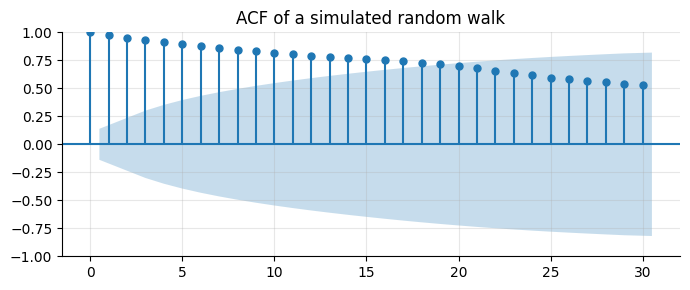

In [15]:
rng = np.random.default_rng(1)
T = 200
eps = rng.normal(0, 1, T)
x = np.cumsum(eps)   # x_t = x_{t-1} + eps_t, starting from x_0 = 0

fig, ax = plt.subplots(figsize=(7, 3))
plot_acf(x, lags=30, ax=ax, title='ACF of a simulated random walk')
plt.tight_layout()
plt.show()

The ACF showed the same slow, smooth decay pattern typically associated with a trending series, even though the process has no deterministic trend built into it anywhere. This happens because each value in a random walk is built almost entirely from the value immediately before it, plus one small new random nudge, so x_t and x_{t-1} share nearly all of the same accumulated history and are highly correlated; the same logic carries through two steps back, three steps back, and so on, so the correlation only fades very slowly rather than dropping off quickly. In other words, the "trend-like" look isn't evidence of a real upward or downward pull in the data, it's a side effect of momentum from accumulating random noise over time, which is exactly why real series with this slow-decaying ACF shape, like Nigeria CPI, need to be checked with formal tools such as a unit root test (e.g. Augmented Dickey-Fuller) rather than assumed to have genuine deterministic trend just from the ACF picture alone.